# Estimate a discrete generalized equivalent layer

### Things we have to import

In [1]:
import numpy as np

In [2]:
import matplotlib.pyplot as plt

In [3]:
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

In [4]:
from scipy.fft import fftfreq, fftshift

In [5]:
import time

In [6]:
import pickle

In [7]:
from gravmag import data_structures, utils, aux_vedo, transforms, inverse_distance, convolve, filters, constants, eqlayer
from gravmag.models import rectangular_prism as rp

In [8]:
import vedo

In [9]:
# set the backend for vedo
vedo.settings.default_backend= 'vtk'
#vedo.settings.default_backend= '2d'

### Set path for saving figures

In [10]:
figures = '../manuscript/figures/'

### Load data

In [11]:
boundary_points = pickle.load(open('model/1_model_boundary_points.pickle', 'rb'))

In [12]:
# append the first point at the end to plot a closed curve
boundary_points = np.vstack([boundary_points, boundary_points[0]])

In [13]:
model = pickle.load(open('model/1_model.pickle', 'rb'))

In [14]:
model_area = pickle.load(open('model/1_model_area.pickle', 'rb'))
model_shape = pickle.load(open('model/1_model_shape.pickle', 'rb'))

In [15]:
mag_intensity = pickle.load(open('model/1_model_mag_intensity.pickle', 'rb'))
mag_inc = pickle.load(open('model/1_model_mag_inc.pickle', 'rb'))
mag_dec = pickle.load(open('model/1_model_mag_dec.pickle', 'rb'))

In [16]:
main_field = pickle.load(open('model/2_main_field.pickle', 'rb'))

In [17]:
print('Main field inc = {}° dec = {}°'.format(main_field['inc'], main_field['dec']))

Main field inc = -30° dec = 10°


In [18]:
simulated_fields = pickle.load(open('model/2_simulated_fields.pickle', 'rb'))

In [19]:
coordinates_grid = pickle.load(open('model/2_coordinates_grid.pickle', 'rb'))

In [20]:
print('Regular grid of coordinates on the horizontal plane {} m'.format(coordinates_grid['z']))

Regular grid of coordinates on the horizontal plane -150 m


In [21]:
Neumanns_predicted_fields = pickle.load(open('model/3a_Neumanns_predicted_fields.pickle', 'rb'))
Neumanns_cutoff_predicted_fields = pickle.load(open('model/3b_Neumanns_cutoff_predicted_fields.pickle', 'rb'))
Neumanns_reg_predicted_fields = pickle.load(open('model/3c_Neumanns_reg_predicted_fields.pickle', 'rb'))

In [22]:
dipole_predicted_fields = pickle.load(open('model/4a_dipole_predicted_fields.pickle', 'rb'))
dipole_cutoff_predicted_fields = pickle.load(open('model/4b_dipole_cutoff_predicted_fields.pickle', 'rb'))
dipole_reg_predicted_fields = pickle.load(open('model/4c_dipole_reg_predicted_fields.pickle', 'rb'))

In [23]:
generic_predicted_fields = pickle.load(open('model/5a_generic_predicted_fields.pickle', 'rb'))
generic_cutoff_predicted_fields = pickle.load(open('model/5b_generic_cutoff_predicted_fields.pickle', 'rb'))
generic_reg_predicted_fields = pickle.load(open('model/5c_generic_reg_predicted_fields.pickle', 'rb'))

In [24]:
Neumanns_layer = pickle.load(open('model/3a_Neumanns_layer.pickle', 'rb'))
Neumanns_layer_cutoff = pickle.load(open('model/3b_Neumanns_layer_cutoff.pickle', 'rb'))
Neumanns_layer_reg = pickle.load(open('model/3c_Neumanns_layer_reg.pickle', 'rb'))

In [25]:
dipole_layer = pickle.load(open('model/4a_dipole_layer.pickle', 'rb'))
dipole_layer_cutoff = pickle.load(open('model/4b_dipole_layer_cutoff.pickle', 'rb'))
dipole_layer_reg = pickle.load(open('model/4c_dipole_layer_reg.pickle', 'rb'))

In [26]:
generic_layer = pickle.load(open('model/5a_generic_layer.pickle', 'rb'))
generic_layer_cutoff = pickle.load(open('model/5b_generic_layer_cutoff.pickle', 'rb'))
generic_layer_reg = pickle.load(open('model/5c_generic_layer_reg.pickle', 'rb'))

In [27]:
Neumanns_k_epsilon_curve = pickle.load(open('model/3b_Neumanns_cutoff_k_epsilon_curve.pickle', 'rb'))
Neumanns_u_epsilon_curve = pickle.load(open('model/3c_Neumanns_reg_mu_epsilon_curve.pickle', 'rb'))

In [28]:
dipole_k_epsilon_curve = pickle.load(open('model/4b_dipole_cutoff_k_epsilon_curve.pickle', 'rb'))
dipole_u_epsilon_curve = pickle.load(open('model/4c_dipole_reg_mu_epsilon_curve.pickle', 'rb'))

In [29]:
generic_k_epsilon_curve = pickle.load(open('model/5b_generic_cutoff_k_epsilon_curve.pickle', 'rb'))
generic_u_epsilon_curve = pickle.load(open('model/5c_generic_reg_mu_epsilon_curve.pickle', 'rb'))

### Get preliminary information from loaded data

In [30]:
# Grid spacing
dx, dy = data_structures.grid_xy_spacing(coordinates_grid['area'], coordinates_grid['shape'])

In [31]:
X, Y = data_structures.grid_xy_to_full_matrices_view(
    x = coordinates_grid['x'],
    y = coordinates_grid['y'],
    shape = coordinates_grid['shape']
)

In [32]:
# Cartesian components of the main field
F_hat = utils.unit_vector(inc=main_field['inc'], dec=main_field['dec'])

In [33]:
# compute a normalized horizontal projection of F_hat to plot
F_hat_horizontal = F_hat[:2]/np.linalg.norm(F_hat[:2])

In [34]:
print('Main field direction inc = {}° dec = {}°'.format(main_field['inc'], main_field['dec']))

Main field direction inc = -30° dec = 10°


In [35]:
# Cartesian components of the model magnetization
v_hat = utils.unit_vector(inc=mag_inc[0], dec=mag_dec[0])

In [36]:
# compute a normalized horizontal projection of v_hat to plot
v_hat_horizontal = v_hat[:2]/np.linalg.norm(v_hat[:2])

In [37]:
print('Synthetic source magnetization inc = {}° dec = {}°'.format(mag_inc[0], mag_dec[0]))

Synthetic source magnetization inc = -10.2° dec = -19.8°


### Plot the equivalent layers

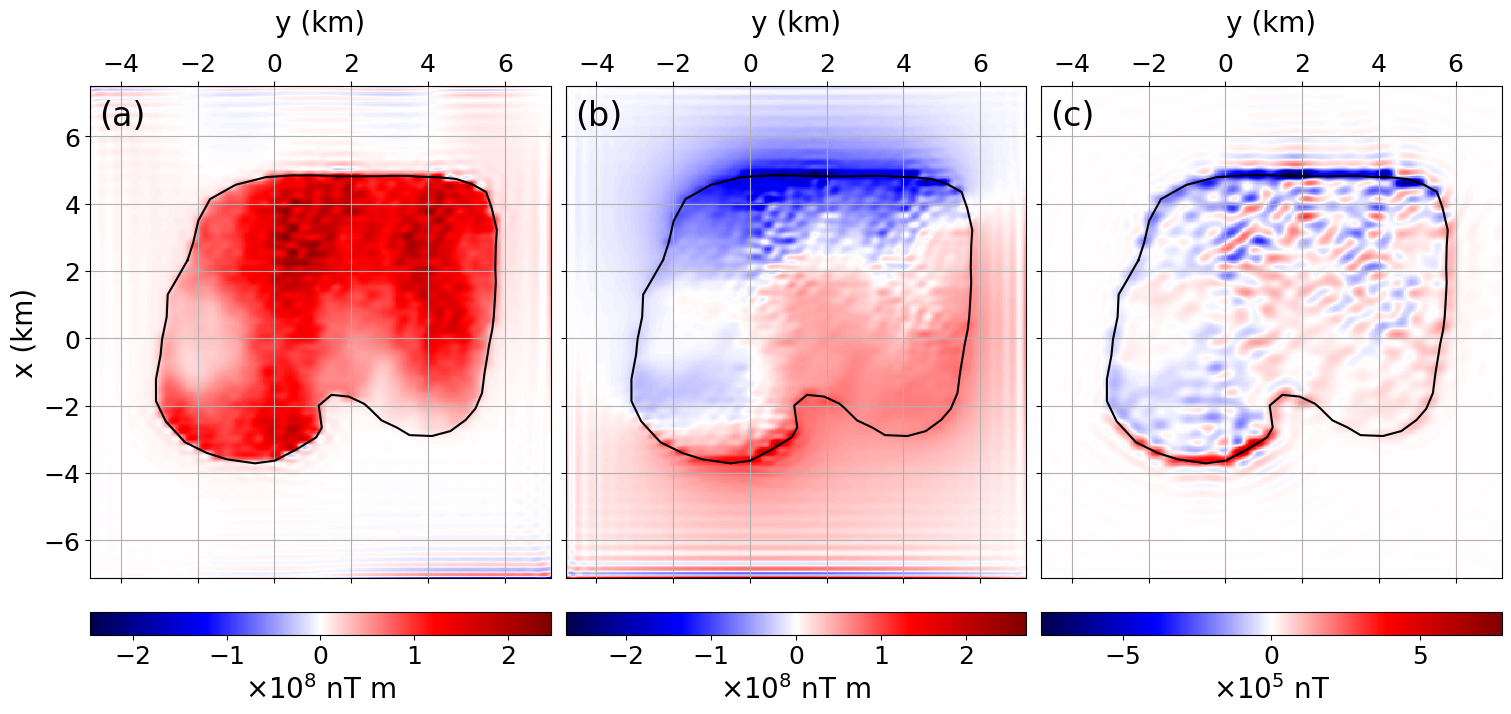

In [38]:
# plot figure
fig = plt.figure(
    layout= 'constrained', 
    figsize=(15,7)
)
mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             ''',
    sharex=True, sharey=True
)

labels = ['(a)', '(b)', '(c)']

mosaic_elements = ['a', 'b', 'c']

units = ['$\\times 10^{8}$ nT m'] + ['$\\times 10^{8}$ nT m'] + ['$\\times 10^{5}$ nT']

ranges = [
    np.max(np.abs(Neumanns_layer))*1e-8,
    np.max(np.abs(dipole_layer))*1e-8,
    np.max(np.abs(generic_layer))*1e-5
]

for (element, layer, label, ranges_layer, unit) in zip(
    mosaic_elements, 
    [1e-8*Neumanns_layer, 1e-8*dipole_layer, 1e-5*generic_layer], 
    labels,
    ranges,
    units,
):
    ax = mosaic[element]
    #ax.axis('scaled')
    im = ax.pcolormesh(
        Y*0.001, X*0.001, 
        data_structures.grid_xy_full_flatten_to_matrix(
            data=layer,
            grid_orientation='xy',
            shape=coordinates_grid['shape']
        ),
        cmap='seismic', vmin=-ranges_layer, vmax=ranges_layer
    )
    # ax_divider = make_axes_locatable(ax)
    # cax = ax_divider.append_axes("bottom", size="7%", pad="17%")
    # cb = fig.colorbar(im, cax=cax, orientation='horizontal')
    # cb.ax.tick_params(labelsize=14, top=False, bottom=True, labeltop=False, labelbottom=True)
    # cb.ax.set_xlabel(unit, fontsize=16, loc='center')
    cb = fig.colorbar(
        im, 
        ax=ax, 
        location='bottom',
    )
    cb.ax.tick_params(labelsize=18, top=False, bottom=True, labeltop=False, labelbottom=True)
    cb.ax.set_xlabel(unit, fontsize=20, loc='center')
    ax.plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')
    ax.set_ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
    ax.set_xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
    ax.tick_params(axis='x', labelsize=18)
    ax.tick_params(axis='y', labelsize=18)
    ax.grid()
    ax.annotate(label, xy=(0.02, 0.92), xycoords='axes fraction', fontsize=24)
    # ax.arrow(x=6, y=5.2, dx=v_hat_horizontal[1], dy=v_hat_horizontal[0], 
    #          width=0.2, length_includes_head=False, head_width=0.6, linewidth=2, color='black') 

# set vertical and horizontal spaces between subplots
#fig.subplots_adjust(wspace=0.20, hspace=0.30)
    
for element in ['a']:
    mosaic[element].set_ylabel('x (km)', fontsize=20)
for element in ['a','b','c']:
    mosaic[element].tick_params(top=True, labeltop=True, bottom=True, labelbottom=False)
    mosaic[element].set_xlabel('y (km)', fontsize=20, loc='center', labelpad=15)
    mosaic[element].xaxis.set_label_position('top')
    
#plt.savefig(figures+'Figure4.png', dpi=300)

plt.show()

In [39]:
layers = [
    [1e-8*Neumanns_layer, 1e-8*dipole_layer, 1e-5*generic_layer],
    [1e-8*Neumanns_layer_cutoff, 1e-8*dipole_layer_cutoff, 1e-5*generic_layer_cutoff],
    [1e-8*Neumanns_layer_reg, 1e-8*dipole_layer_reg, 1e-5*generic_layer_reg]
]

In [40]:
units = ['$\\times 10^{8}$ nT m'] + ['$\\times 10^{8}$ nT m'] + ['$\\times 10^{5}$ nT']

ranges_layers = [
    np.max(np.abs(Neumanns_layer))*1e-8,
    np.max(np.abs(dipole_layer))*1e-8,
    np.max(np.abs(generic_layer))*1e-5
]

In [41]:
diff_layers = [
    [
        1e-8*Neumanns_layer_cutoff - 1e-8*Neumanns_layer, 
        1e-8*dipole_layer_cutoff - 1e-8*dipole_layer, 
        1e-5*generic_layer_cutoff - 1e-5*generic_layer
    ],
    [
        1e-8*Neumanns_layer_reg - 1e-8*Neumanns_layer, 
        1e-8*dipole_layer_reg - 1e-8*dipole_layer, 
        1e-5*generic_layer_reg - 1e-5*generic_layer
    ]
]

In [42]:
ranges_diff_layers = list()
ranges_diff_layers.append(np.max(np.abs([diff_layers[0][0], diff_layers[1][0]]))) # bounds Neumanns's layers
ranges_diff_layers.append(np.max(np.abs([diff_layers[0][1], diff_layers[1][1]]))) # bounds dipoles layers
ranges_diff_layers.append(np.max(np.abs([diff_layers[0][2], diff_layers[1][2]]))) # bounds generic layers

In [43]:
for diffs_row in diff_layers:
    for diff in diffs_row:
        print(np.max(np.abs(diff)))

1.4390064428905542
2.397137952572464
1.3727816007628544
1.4392393155258831
2.433886029441305
1.4675897183361584


In [44]:
ranges_diff_layers

[1.4392393155258831, 2.433886029441305, 1.4675897183361584]

In [45]:
curves = [
    [
        Neumanns_k_epsilon_curve,
        dipole_k_epsilon_curve,
        generic_k_epsilon_curve
    ],
    [
        Neumanns_u_epsilon_curve,
        dipole_u_epsilon_curve,
        generic_u_epsilon_curve
    ]
]

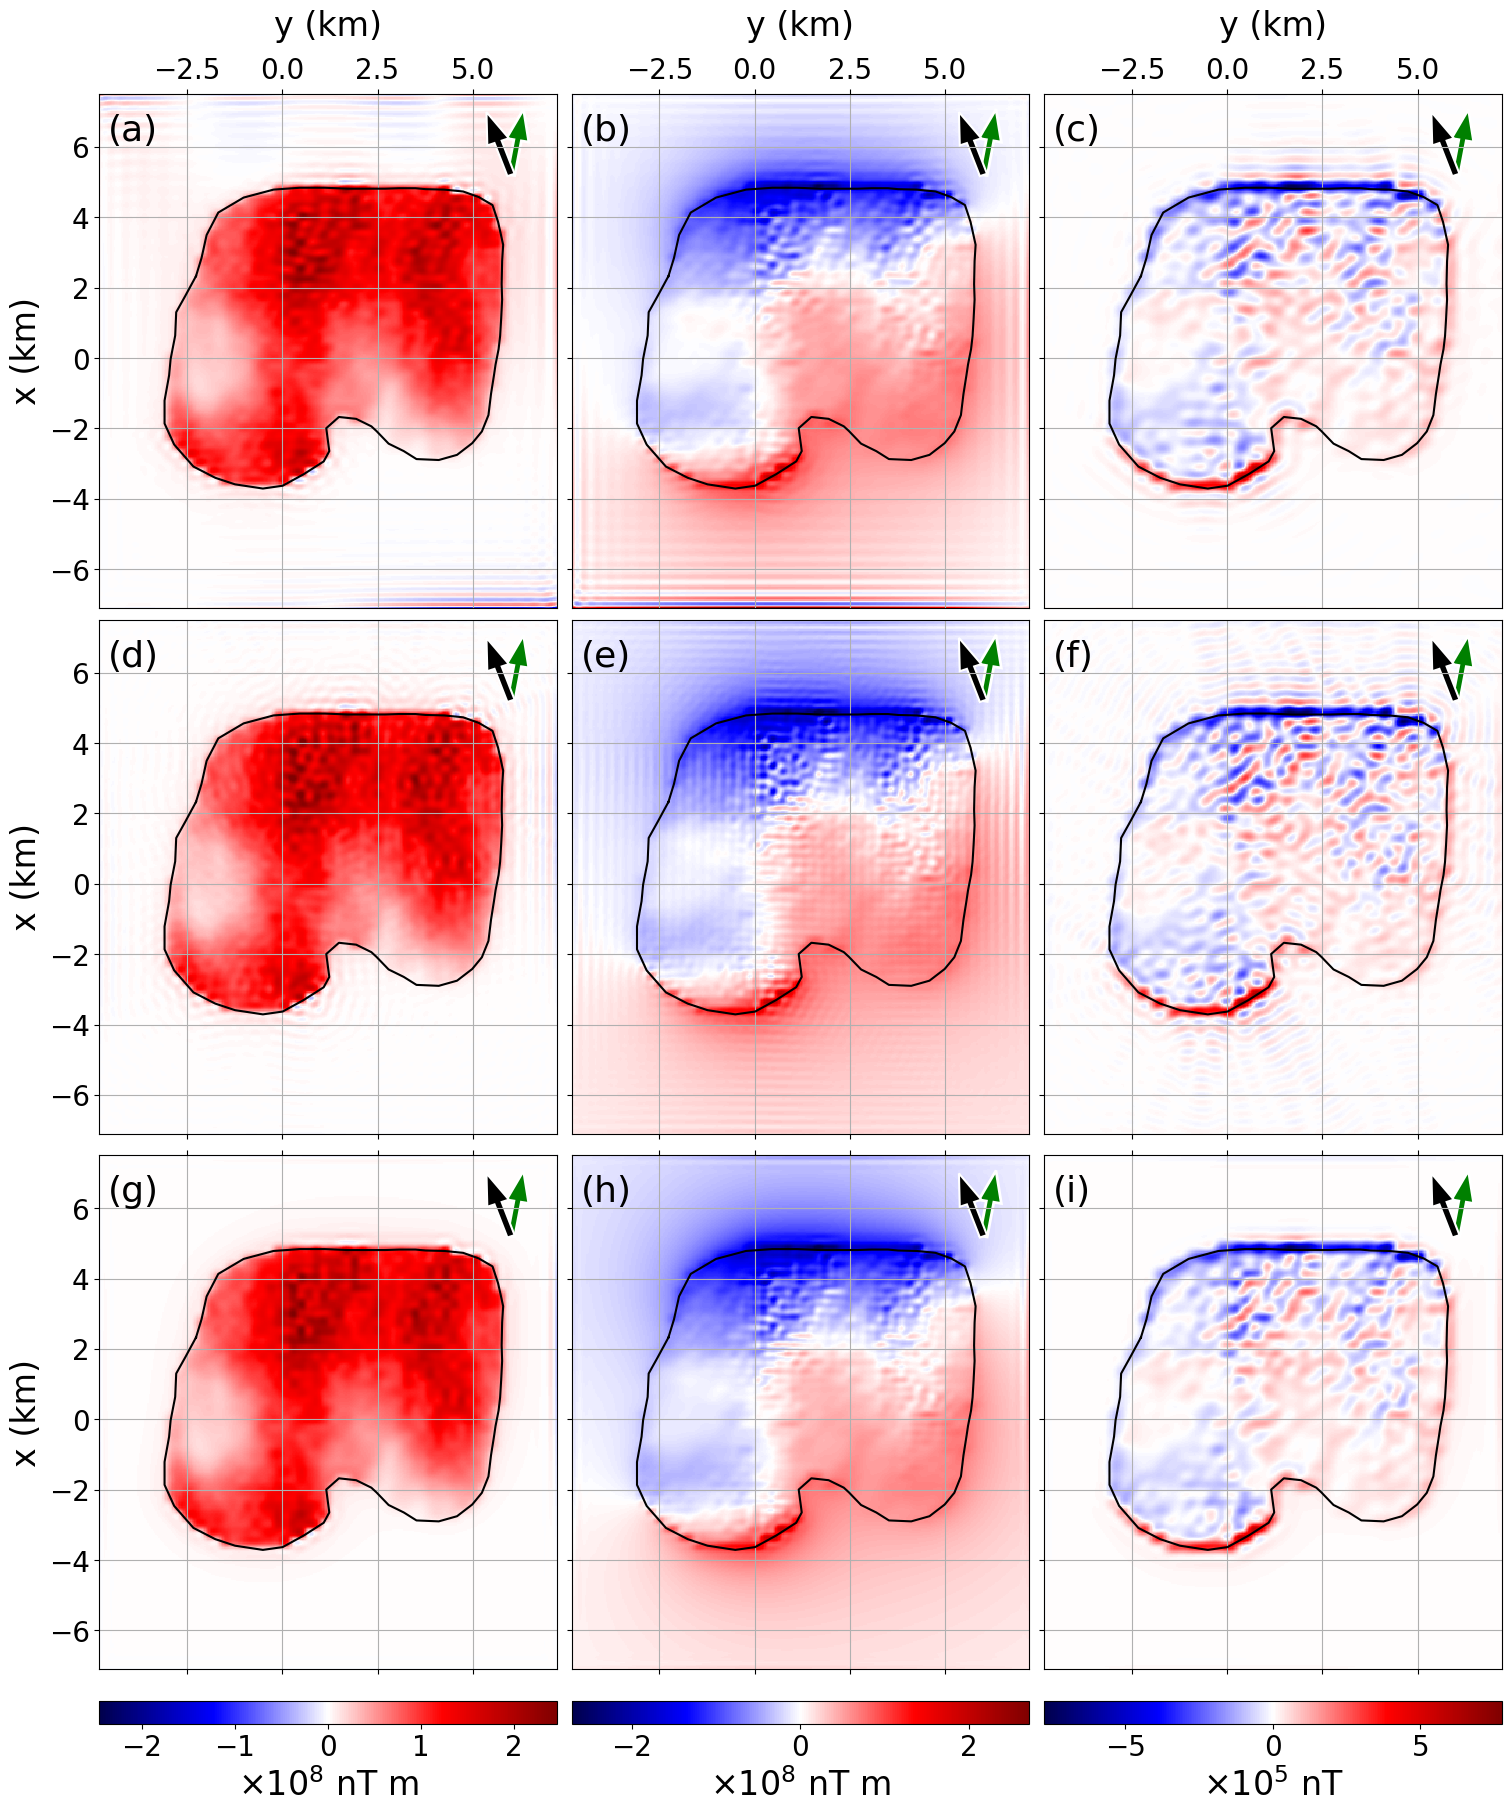

In [46]:
# plot figure
fig = plt.figure(
    layout= 'constrained', 
    figsize=(15,18)
)

mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             def
             ghi
             ''',
    sharex=True, sharey=True
)

labels = [
    ['(a)', '(b)', '(c)'], 
    ['(d)', '(e)', '(f)'], 
    ['(g)', '(h)', '(i)']
]

mosaic_elements = [
    ['a', 'b', 'c'], 
    ['d', 'e', 'f'], 
    ['g', 'h', 'i']
]

for (mosaic_row, labels_row, layers_row) in zip(
    mosaic_elements, 
    labels,
    layers
):
    
    for mosaic_element, label, layer, ranges_layer in zip(mosaic_row, labels_row, layers_row, ranges_layers):
    
        ax = mosaic[mosaic_element]
        #ax.axis('scaled')
        im = ax.pcolormesh(
            Y*0.001, X*0.001, 
            data_structures.grid_xy_full_flatten_to_matrix(
                data=layer,
                grid_orientation='xy',
                shape=coordinates_grid['shape']
            ),
            cmap='seismic', 
            #vmin=-bound, vmax=bound
            vmin=-ranges_layer, vmax=ranges_layer
        )
        
        ax.plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')
        ax.set_ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
        ax.set_xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
        ax.tick_params(axis='x', labelsize=20)
        ax.tick_params(axis='y', labelsize=20)
        ax.grid()
        ax.annotate(label, xy=(0.02, 0.91), xycoords='axes fraction', fontsize=26)
        ax.arrow(x=6, y=5.2, dx=F_hat_horizontal[1], dy=F_hat_horizontal[0], 
             width=0.2, length_includes_head=False, head_width=0.6, linewidth=2, fc='green', ec='white') 
        ax.arrow(
            x=6, y=5.2, dx=v_hat_horizontal[1], dy=v_hat_horizontal[0], 
            width=0.2, length_includes_head=False, head_width=0.6, linewidth=1.5, fc='black', ec='white'
        )
    
for element in ['a','d','g']:
    mosaic[element].set_ylabel('x (km)', fontsize=24)
for element in ['a','b', 'c']:
    mosaic[element].tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)
    mosaic[element].set_xlabel('y (km)', fontsize=24, loc='center', labelpad=15)
    mosaic[element].xaxis.set_label_position('top')
for element in ['g','h', 'i']:
    mosaic[element].tick_params(top=True, bottom=True, labelbottom=False)

cb = fig.colorbar(
    mosaic['a'].collections[0], 
    ax=mosaic['g'], 
    location='bottom'
)
cb.ax.tick_params(labelsize=20)
cb.ax.set_xlabel(units[0], fontsize=24, loc='center')

cb = fig.colorbar(
    mosaic['b'].collections[0], 
    ax=mosaic['h'], 
    location='bottom'
)
cb.ax.tick_params(labelsize=20)
cb.ax.set_xlabel(units[1], fontsize=24, loc='center')

cb = fig.colorbar(
    mosaic['c'].collections[0], 
    ax=mosaic['i'], 
    location='bottom'
)
cb.ax.tick_params(labelsize=20)
cb.ax.set_xlabel(units[2], fontsize=24, loc='center')

plt.savefig(figures+'Figure2_4.png', dpi=300)

plt.show()

(a): ke = 0.020
(b): ke = 0.025
(c): ke = 0.015
(d): ue = 5.854
(e): ue = 1.000
(f): ue = 49.889


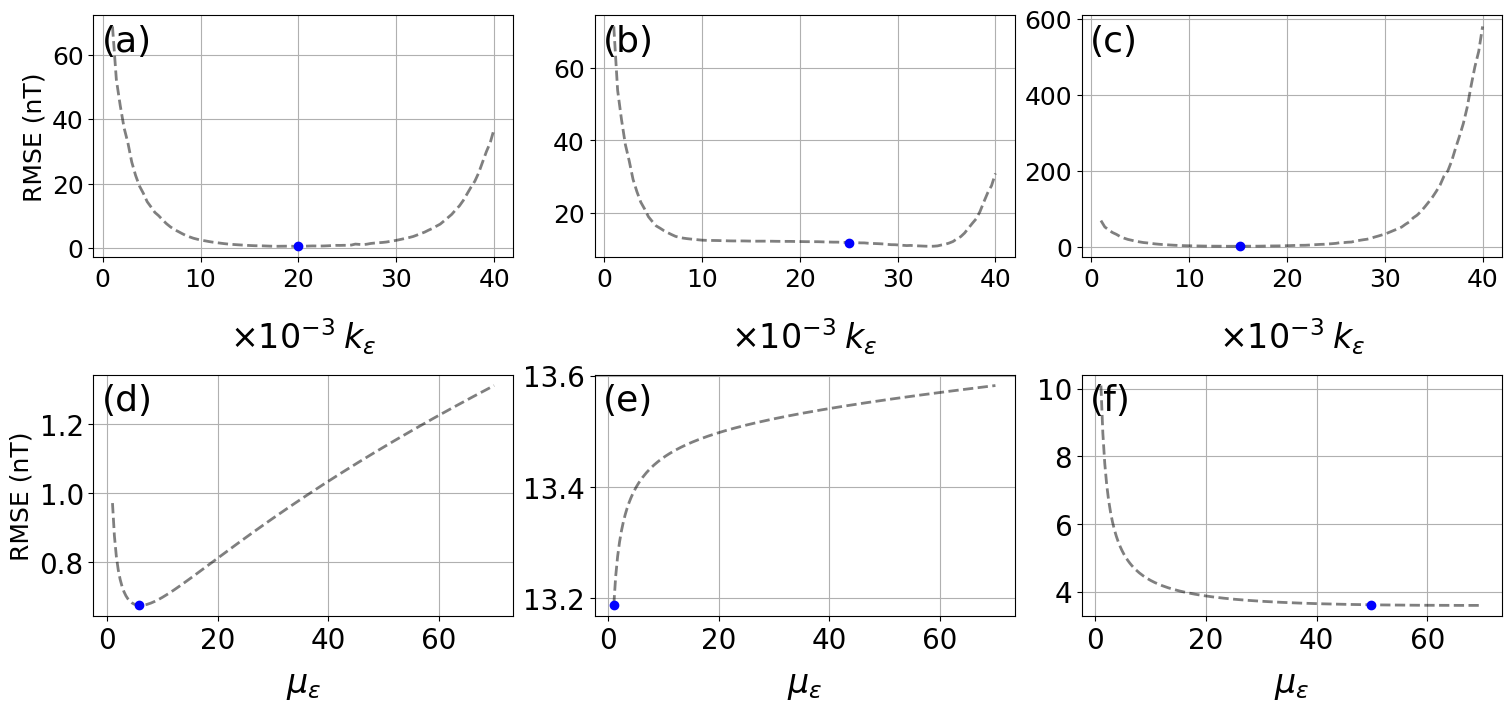

In [56]:
# plot figure
fig = plt.figure(
    layout= 'constrained', 
    figsize=(15,7)
)

mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             def
             ''',
    sharex=False, sharey=False
)

labels = [
    ['(a)', '(b)', '(c)'], 
    ['(d)', '(e)', '(f)']
]

mosaic_elements = [
    ['a', 'b', 'c'], 
    ['d', 'e', 'f']
]

for (mosaic_row, labels_row, curves_row, parameter, factor) in zip(
    mosaic_elements, 
    labels,
    curves,
    ['ke','ue'],
    [1e3, 1]
):
    
    for mosaic_element, label, curve in zip(mosaic_row, labels_row, curves_row):
    
        ax = mosaic[mosaic_element]
        ax.plot(factor*curve[parameter], curve['rmse'], 'k--', lw=2, alpha=0.5)
        ax.plot([factor*curve[parameter][curve['chosen']]], [curve['rmse'][curve['chosen']]], 'bo', lw=20)
        ax.grid()
        ax.annotate(label, xy=(0.02, 0.85), xycoords='axes fraction', fontsize=26)
        print(f"{label}: {parameter} = {curve[parameter][curve['chosen']]:>5.3f}")
    
for element in ['a','d']:
    mosaic[element].set_ylabel('RMSE (nT)', fontsize=18)
for element in ['a', 'b', 'c']:
    mosaic[element].tick_params(top=False, labeltop=False, bottom=True, labelbottom=True, labelsize=18)
    mosaic[element].set_xlabel('$\\times 10^{-3} \: k_{\\varepsilon}$', fontsize=24, loc='center', labelpad=18)
    mosaic[element].xaxis.set_label_position('bottom')
for element in ['d', 'e', 'f']:
    mosaic[element].tick_params(top=False, labeltop=False, bottom=True, labelbottom=True, labelsize=20)
    mosaic[element].set_xlabel('$\mu_{\\varepsilon}$', fontsize=24, loc='center', labelpad=10)
    mosaic[element].xaxis.set_label_position('bottom')


plt.savefig(figures+'Figure_S1.png', dpi=300)

plt.show()

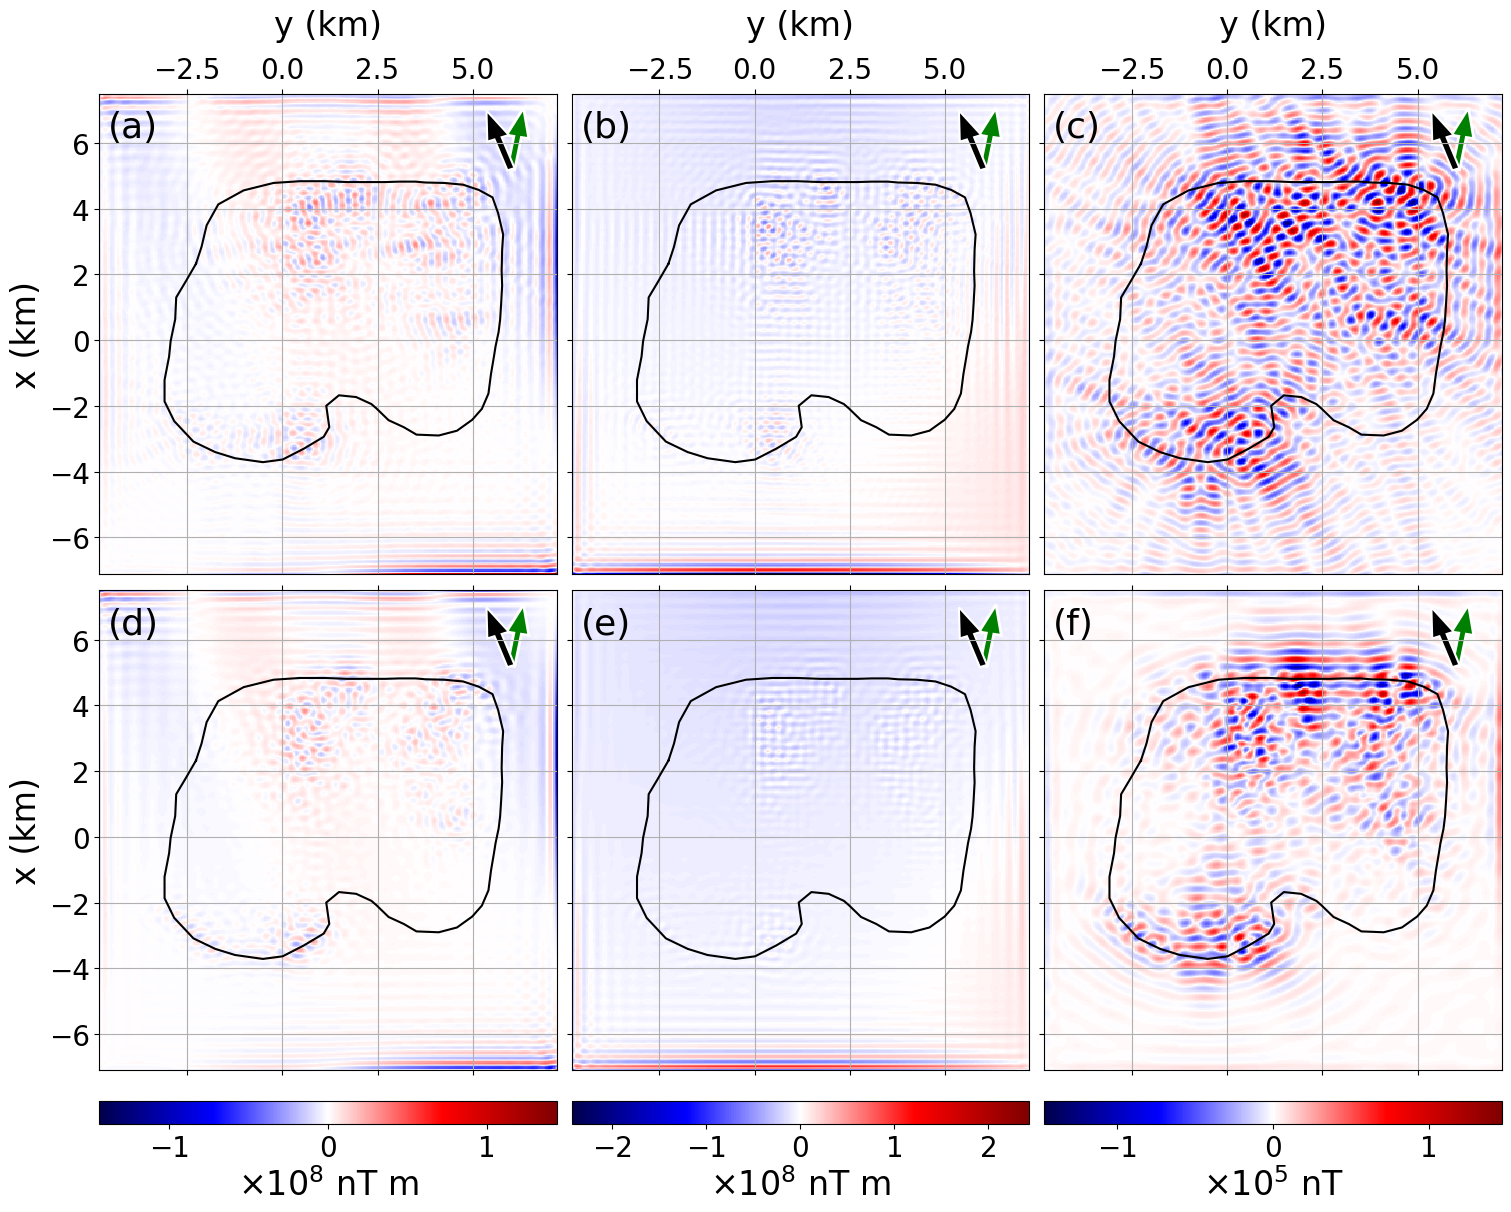

In [48]:
# plot figure
fig = plt.figure(
    layout= 'constrained', 
    figsize=(15,12)
)

mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             def
             ''',
    sharex=True, sharey=True
)

labels = [
    ['(a)', '(b)', '(c)'], 
    ['(d)', '(e)', '(f)']
]

mosaic_elements = [
    ['a', 'b', 'c'], 
    ['d', 'e', 'f']
]

for (mosaic_row, labels_row, diff_layers_row) in zip(
    mosaic_elements, 
    labels,
    diff_layers
):
    
    for mosaic_element, label, diff, ranges_diff_layer in zip(mosaic_row, labels_row, diff_layers_row, ranges_diff_layers):
    
        ax = mosaic[mosaic_element]
        #ax.axis('scaled')
        im = ax.pcolormesh(
            Y*0.001, X*0.001, 
            data_structures.grid_xy_full_flatten_to_matrix(
                data=diff,
                grid_orientation='xy',
                shape=coordinates_grid['shape']
            ),
            cmap='seismic', 
            #vmin=-bound, vmax=bound
            vmin=-ranges_diff_layer, vmax=ranges_diff_layer
        )
        
        ax.plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')
        ax.set_ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
        ax.set_xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
        ax.tick_params(axis='x', labelsize=20)
        ax.tick_params(axis='y', labelsize=20)
        ax.grid()
        ax.annotate(label, xy=(0.02, 0.91), xycoords='axes fraction', fontsize=26)
        ax.arrow(x=6, y=5.2, dx=F_hat_horizontal[1], dy=F_hat_horizontal[0], 
             width=0.2, length_includes_head=False, head_width=0.6, linewidth=2, fc='green', ec='white') 
        ax.arrow(
            x=6, y=5.2, dx=v_hat_horizontal[1], dy=v_hat_horizontal[0], 
            width=0.2, length_includes_head=False, head_width=0.6, linewidth=1.5, fc='black', ec='white'
        )
    
for element in ['a','d']:
    mosaic[element].set_ylabel('x (km)', fontsize=24)
for element in ['a','b','c']:
    mosaic[element].tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)
    mosaic[element].set_xlabel('y (km)', fontsize=24, loc='center', labelpad=15)
    mosaic[element].xaxis.set_label_position('top')
for element in ['d','e','f']:
    mosaic[element].tick_params(top=True, bottom=True, labelbottom=False)

cb = fig.colorbar(
    mosaic['a'].collections[0], 
    ax=mosaic['d'], 
    location='bottom'
)
cb.ax.tick_params(labelsize=20)
cb.ax.set_xlabel(units[0], fontsize=24, loc='center')

cb = fig.colorbar(
    mosaic['b'].collections[0], 
    ax=mosaic['e'], 
    location='bottom'
)
cb.ax.tick_params(labelsize=20)
cb.ax.set_xlabel(units[1], fontsize=24, loc='center')

cb = fig.colorbar(
    mosaic['c'].collections[0], 
    ax=mosaic['f'], 
    location='bottom'
)
cb.ax.tick_params(labelsize=20)
cb.ax.set_xlabel(units[2], fontsize=24, loc='center')

plt.savefig(figures+'Figure_S2.png', dpi=300)

plt.show()

### Plot the data fit

In [49]:
# set a common bound for all mosaic panels
common_bound = list()
for field in ['atfa', 'b', 'rtp', 'bx', 'by', 'bz']:
    data_list = [
        Neumanns_predicted_fields[field] - simulated_fields[field],
        dipole_predicted_fields[field] - simulated_fields[field],
        generic_predicted_fields[field] - simulated_fields[field]
    ]
    common_bound.append(np.max(np.abs(data_list)))

common_bound = 0.8*np.max(common_bound)

In [50]:
common_bound

56.06230767216721

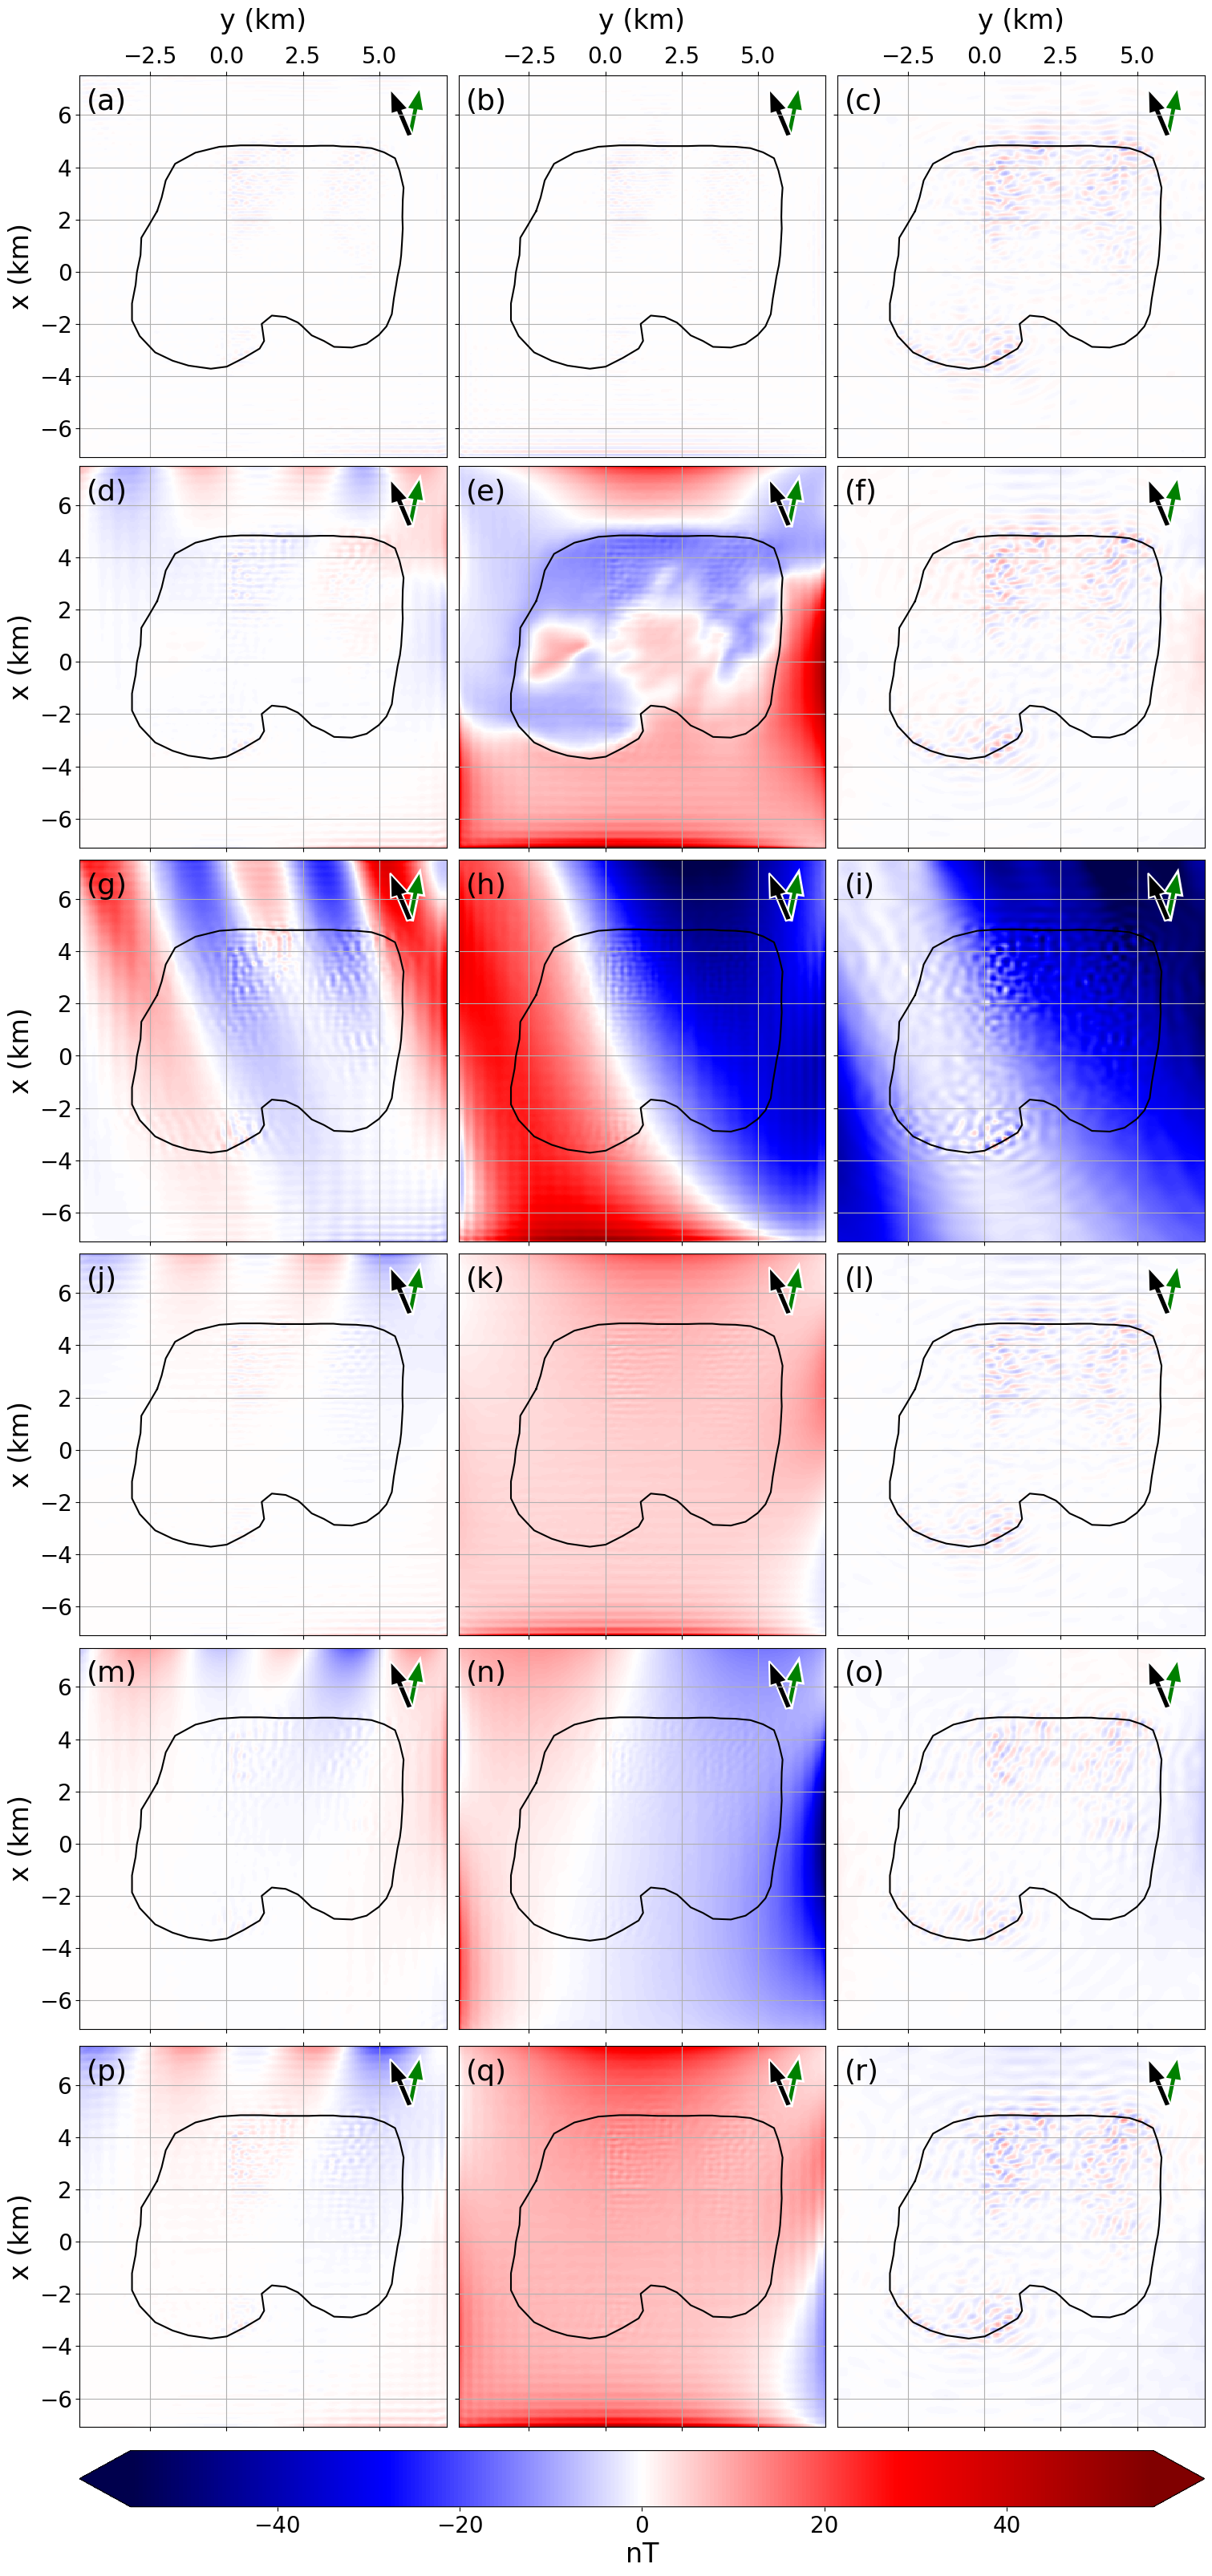

In [51]:
# plot figure
fig = plt.figure(
    layout= 'constrained', 
    figsize=(15,32)
)

# set vertical and horizontal spaces between subplots
#fig.subplots_adjust(wspace=0.0, hspace=0.0)

mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             def
             ghi
             jkl
             mno
             pqr
             ''',
    sharex=True, sharey=True
)

labels = [
    ['(a)', '(b)', '(c)'], 
    ['(d)', '(e)', '(f)'], 
    ['(g)', '(h)', '(i)'], 
    ['(j)', '(k)', '(l)'], 
    ['(m)', '(n)', '(o)'],
    ['(p)', '(q)', '(r)']
]

mosaic_elements = [
    ['a', 'b', 'c'], 
    ['d', 'e', 'f'], 
    ['g', 'h', 'i'], 
    ['j', 'k', 'l'], 
    ['m', 'n', 'o'],
    ['p', 'q', 'r']
]

for (mosaic_row, labels_row, field) in zip(
    mosaic_elements, 
    labels,
    ['atfa', 'b', 'rtp', 'bx', 'by', 'bz']
):
    data_list = [
        Neumanns_predicted_fields[field] - simulated_fields[field],
        dipole_predicted_fields[field] - simulated_fields[field],
        generic_predicted_fields[field] - simulated_fields[field]
    ]
    #bound = np.max(np.abs(data_list))
    
    for mosaic_element, data, label in zip(mosaic_row, data_list, labels_row):
    
        ax = mosaic[mosaic_element]
        #ax.axis('scaled')
        im = ax.pcolormesh(
            Y*0.001, X*0.001, 
            data_structures.grid_xy_full_flatten_to_matrix(
                data=data,
                grid_orientation='xy',
                shape=coordinates_grid['shape']
            ),
            cmap='seismic', 
            #vmin=-bound, vmax=bound
            vmin=-common_bound, vmax=common_bound
        )
        
        ax.plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')
        ax.set_ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
        ax.set_xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
        ax.tick_params(axis='x', labelsize=20)
        ax.tick_params(axis='y', labelsize=20)
        ax.grid()
        ax.annotate(label, xy=(0.02, 0.91), xycoords='axes fraction', fontsize=26)
        ax.arrow(x=6, y=5.2, dx=F_hat_horizontal[1], dy=F_hat_horizontal[0], 
             width=0.2, length_includes_head=False, head_width=0.6, linewidth=2, fc='green', ec='white') 
        ax.arrow(
            x=6, y=5.2, dx=v_hat_horizontal[1], dy=v_hat_horizontal[0], 
            width=0.2, length_includes_head=False, head_width=0.6, linewidth=1.5, fc='black', ec='white'
        )
    
    # put a colorbar in the rightmost panel of the row
    # ax_divider = make_axes_locatable(ax)
    # cax = ax_divider.append_axes("right", size="5%", pad="2%")
    # cb = fig.colorbar(im, cax=cax)
    # cb.ax.tick_params(labelsize=20)
    #cb.ax.set_xlabel('nT', fontsize=22, loc='left')
    
for element in ['a','d','g', 'j', 'm', 'p']:
    mosaic[element].set_ylabel('x (km)', fontsize=24)
for element in ['a','b', 'c']:
    mosaic[element].tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)
    mosaic[element].set_xlabel('y (km)', fontsize=24, loc='center', labelpad=15)
    mosaic[element].xaxis.set_label_position('top')
for element in ['p','q', 'r']:
    mosaic[element].tick_params(top=True, bottom=True, labelbottom=False)

cb = fig.colorbar(
    mosaic['h'].collections[0], 
    ax=[mosaic['p'], mosaic['q'], mosaic['r']], 
    location='bottom',
    extend='both'
)
cb.ax.tick_params(labelsize=20)
cb.ax.set_xlabel('nT', fontsize=24, loc='center')

plt.savefig(figures+'Figure2_5.png', dpi=300)

plt.show()